# Лабораторна робота 9. Тонке налаштування (Fine Tuning): ResNet50

## Завантаження набору даних з Google Диска

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import glob, shutil

# шукаємо архів dogs-vs-cats.zip з Kaggle у будь-якій папці Google Диска
found = glob.glob('/content/drive/MyDrive/**/dogs-vs-cats*.zip', recursive=True)
print(found)
assert found, 'Архів dogs-vs-cats.zip не знайдено на Google Диску'
shutil.copy(found[0], '/content/dogs-vs-cats.zip')

['/content/drive/MyDrive/dogs-vs-cats.zip']


'/content/dogs-vs-cats.zip'

In [3]:
# розпаковуємо архів з Kaggle, а потім train.zip з 25 000 зображень
!unzip -q -o /content/dogs-vs-cats.zip -d /content/dogs-vs-cats
!unzip -q -o /content/dogs-vs-cats/train.zip -d /content/dogs-vs-cats
!ls /content/dogs-vs-cats/train | wc -l

25000


## Підготовка набору даних (скрипт prepare_dataset.py з лабораторної роботи 7)

In [4]:
%%writefile prepare_dataset.py
"""Підготовка набору даних Dogs vs. Cats для навчання нейронної мережі в Keras.

Зображення з каталогу data_dir (25 000 файлів cat.N.jpg і dog.N.jpg з Kaggle) розподіляються
на три набори: для навчання (70%), перевірки (15%) і тестування (15%).
У кожному наборі створюються підкаталоги cats і dogs, як потрібно для flow_from_directory.
"""
import os
import shutil

# Каталог з набором даних (розпакований train.zip з Kaggle)
data_dir = '/content/dogs-vs-cats/train'
# Каталог з даними для навчання
train_dir = 'train'
# Каталог з даними для перевірки
val_dir = 'val'
# Каталог з даними для тестування
test_dir = 'test'
# Частина набору даних для тестування
test_data_portion = 0.15
# Частина набору даних для перевірки
val_data_portion = 0.15
# Кількість зображень в одному класі
nb_images = 12500


def create_directory(dir_name):
    """Створює каталог dir_name з підкаталогами cats і dogs (старий каталог видаляється)."""
    if os.path.exists(dir_name):
        shutil.rmtree(dir_name)
    os.makedirs(dir_name)
    os.makedirs(os.path.join(dir_name, "cats"))
    os.makedirs(os.path.join(dir_name, "dogs"))


def copy_images(start_index, end_index, source_dir, dest_dir):
    """Копіює зображення котів і собак з номерами від start_index до end_index у підкаталоги cats і dogs."""
    for i in range(start_index, end_index):
        shutil.copy2(os.path.join(source_dir, "cat." + str(i) + ".jpg"),
                     os.path.join(dest_dir, "cats"))
        shutil.copy2(os.path.join(source_dir, "dog." + str(i) + ".jpg"),
                     os.path.join(dest_dir, "dogs"))


create_directory(train_dir)
create_directory(val_dir)
create_directory(test_dir)

# Індекси, з яких починаються набори для перевірки і тестування
start_val_data_idx = int(nb_images * (1 - val_data_portion - test_data_portion))
start_test_data_idx = int(nb_images * (1 - test_data_portion))
print(start_val_data_idx)
print(start_test_data_idx)

copy_images(0, start_val_data_idx, data_dir, train_dir)
copy_images(start_val_data_idx, start_test_data_idx, data_dir, val_dir)
copy_images(start_test_data_idx, nb_images, data_dir, test_dir)

for d in (train_dir, val_dir, test_dir):
    print(d, ': cats -', len(os.listdir(os.path.join(d, "cats"))), ', dogs -', len(os.listdir(os.path.join(d, "dogs"))))

Writing prepare_dataset.py


In [5]:
!python prepare_dataset.py

8750
10625
train : cats - 8750 , dogs - 8750
val : cats - 1875 , dogs - 1875
test : cats - 1875 , dogs - 1875


## Підключаємо бібліотеки

In [6]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, BatchNormalization
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.utils import load_img, img_to_array

## Константи

In [7]:
# Каталог з даними для навчання
train_dir = 'train'
# Каталог з даними для перевірки
val_dir = 'val'
# Каталог з даними для тестування
test_dir = 'test'
# Розміри зображення
img_width, img_height = 150, 150
# Розмірність тензору на основі зображення для вхідних даних в нейронну мережу
input_shape = (img_width, img_height, 3)
# Кількість епох
epochs = 10
# Розмір міні-вибірки
batch_size = 16

## Генератори зображень

In [8]:
# для ResNet50 зображення обробляються функцією preprocess_input (документація Keras)
datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

def make_generator(directory, batch_size=64, shuffle=False):
    return datagen.flow_from_directory(directory,
                                       target_size=(img_width, img_height),
                                       batch_size=batch_size,
                                       class_mode='binary',
                                       shuffle=shuffle)

# генератори без перемішування для обчислення ознак (мітки беремо з generator.classes)
train_generator = make_generator(train_dir)
val_generator = make_generator(val_dir)
test_generator = make_generator(test_dir)
print(train_generator.class_indices)

Found 17500 images belonging to 2 classes.
Found 3750 images belonging to 2 classes.
Found 3750 images belonging to 2 classes.
{'cats': 0, 'dogs': 1}


## Попередньо навчена мережа ResNet50 без частини для класифікації

In [9]:
def load_base():
    """Попередньо навчена згорткова частина ResNet50 без класифікатора, заморожена."""
    net = ResNet50(weights='imagenet',
                   include_top=False,
                   input_shape=input_shape,
                   # усереднення карт ознак, як у лабораторній роботі 8 (інакше ознаки не вміщуються в пам'ять)
                   pooling='avg')
    net.trainable = False
    return net


resnet_net = load_base()
print('Шарів у мережі:', len(resnet_net.layers))
print('Вихід згорткової частини:', resnet_net.output_shape)
print('Параметрів:', resnet_net.count_params())

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Шарів у мережі: 176
Вихід згорткової частини: (None, 2048)
Параметрів: 23587712


## Обчислення ознак замороженої згорткової частини

In [10]:
# згорткова частина заморожена, тому для підбору гіперпараметрів класифікатора
# кожне зображення достатньо пропустити через неї один раз
train_features = resnet_net.predict(train_generator, verbose=1)
val_features = resnet_net.predict(val_generator, verbose=1)
test_features = resnet_net.predict(test_generator, verbose=1)
train_labels, val_labels, test_labels = train_generator.classes, val_generator.classes, test_generator.classes
print('Ознаки:', train_features.shape, val_features.shape, test_features.shape)

274/274 ━━━━━━━━━━━━━━━━━━━━ 60s 193ms/step
59/59 ━━━━━━━━━━━━━━━━━━━━ 13s 226ms/step
59/59 ━━━━━━━━━━━━━━━━━━━━ 9s 157ms/step
Ознаки: (17500, 2048) (3750, 2048) (3750, 2048)


## Підбір гіперпараметрів класифікатора (перенесення навчання)

In [11]:
def plot_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='навчальна')
    plt.plot(epochs_range, val_acc, label='перевірочна')
    plt.title(title + ': точність'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='навчальна')
    plt.plot(epochs_range, val_loss, label='перевірочна')
    plt.title(title + ': помилка (loss)'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.show()

In [12]:
def make_optimizer(name, lr):
    """Оптимізатор за назвою; lr=None - швидкість навчання за замовчуванням у Keras."""
    if name == 'adam':
        return Adam(learning_rate=lr) if lr else Adam()
    if name == 'rmsprop':
        return RMSprop(learning_rate=lr) if lr else RMSprop()
    return SGD(learning_rate=lr) if lr else SGD()


def create_classifier(cfg, input_shape):
    """Класифікатор з лабораторної роботи 8 з параметрами з cfg: Flatten, Dense, Dropout, [Dense], Dense 1."""
    classifier = Sequential()
    classifier.add(Input(shape=input_shape))
    classifier.add(Flatten())
    classifier.add(Dense(cfg['dense'], activation='relu'))
    classifier.add(Dropout(cfg['dropout']))
    if cfg['extra_dense']:
        classifier.add(Dense(cfg['extra_dense'], activation='relu'))
    classifier.add(Dense(1, activation='sigmoid'))
    classifier.compile(loss='binary_crossentropy',
                       optimizer=make_optimizer(cfg['optimizer'], cfg['lr']),
                       metrics=['accuracy'])
    return classifier


def run_config(cfg, epochs):
    clf = create_classifier(cfg, train_features.shape[1:])
    hist = clf.fit(train_features, train_labels, batch_size=cfg['batch'], epochs=epochs,
                   validation_data=(val_features, val_labels), verbose=0)
    return clf, hist


results = []
# початкові значення - як у лабораторній роботі 8 і в лекції
current = {'dense': 256, 'dropout': 0.5, 'extra_dense': 0, 'optimizer': 'adam', 'lr': 1e-5, 'batch': 25, 'epochs': 10}


def experiment(title, param, values):
    """Перебирає значення одного гіперпараметра, решта - найкращі знайдені раніше."""
    print(title)
    best = None
    for v in values:
        cfg = dict(current, **{param: v})
        if param == 'optimizer':
            cfg['lr'] = None                     # порівнюємо оптимізатори з їхньою швидкістю за замовчуванням
        clf, h = run_config(cfg, cfg['epochs'])
        row = dict(cfg, експеримент=title, train_acc=h.history['accuracy'][-1],
                   val_acc=h.history['val_accuracy'][-1], val_loss=h.history['val_loss'][-1])
        results.append(row)
        print(f"  {param} = {v}: навчальна {row['train_acc']*100:.2f}%, перевірочна {row['val_acc']*100:.2f}%, "
              f"помилка на перевірочних {row['val_loss']:.4f}")
        if best is None or row['val_acc'] > best[0]:
            best = (row['val_acc'], v, cfg['lr'])
    current[param] = best[1]
    if param == 'optimizer':
        current['lr'] = best[2]
    print(f"  найкраще: {param} = {best[1]}\n")

### Кількість нейронів у шарі Dense

In [13]:
experiment('1. Кількість нейронів у шарі Dense', 'dense', [32, 128, 256, 512, 1024])

1. Кількість нейронів у шарі Dense
  dense = 32: навчальна 96.65%, перевірочна 97.20%, помилка на перевірочних 0.0703
  dense = 128: навчальна 97.42%, перевірочна 97.68%, помилка на перевірочних 0.0636
  dense = 256: навчальна 97.78%, перевірочна 97.84%, помилка на перевірочних 0.0619
  dense = 512: навчальна 98.03%, перевірочна 97.97%, помилка на перевірочних 0.0599
  dense = 1024: навчальна 98.47%, перевірочна 97.92%, помилка на перевірочних 0.0597
  найкраще: dense = 512



### Dropout

In [14]:
experiment('2. Dropout', 'dropout', [0.25, 0.5, 0.6, 0.8])

2. Dropout
  dropout = 0.25: навчальна 98.63%, перевірочна 97.60%, помилка на перевірочних 0.0625
  dropout = 0.5: навчальна 98.07%, перевірочна 97.89%, помилка на перевірочних 0.0591
  dropout = 0.6: навчальна 97.87%, перевірочна 97.65%, помилка на перевірочних 0.0599
  dropout = 0.8: навчальна 97.05%, перевірочна 97.63%, помилка на перевірочних 0.0625
  найкраще: dropout = 0.5



### Додатковий шар Dense перед вихідним

In [15]:
experiment('3. Додатковий шар Dense', 'extra_dense', [0, 32, 128, 256])

3. Додатковий шар Dense
  extra_dense = 0: навчальна 98.20%, перевірочна 97.60%, помилка на перевірочних 0.0620
  extra_dense = 32: навчальна 97.98%, перевірочна 97.79%, помилка на перевірочних 0.0628
  extra_dense = 128: навчальна 97.89%, перевірочна 97.81%, помилка на перевірочних 0.0617
  extra_dense = 256: навчальна 97.89%, перевірочна 97.55%, помилка на перевірочних 0.0627
  найкраще: extra_dense = 128



### Оптимізатор

In [16]:
experiment('4. Оптимізатор (швидкість навчання за замовчуванням)', 'optimizer', ['sgd', 'adam', 'rmsprop'])

4. Оптимізатор (швидкість навчання за замовчуванням)
  optimizer = sgd: навчальна 98.83%, перевірочна 97.81%, помилка на перевірочних 0.0667
  optimizer = adam: навчальна 98.64%, перевірочна 97.60%, помилка на перевірочних 0.0672
  optimizer = rmsprop: навчальна 98.34%, перевірочна 97.71%, помилка на перевірочних 0.0726
  найкраще: optimizer = sgd



### Початкова швидкість навчання

In [17]:
experiment('5. Початкова швидкість навчання', 'lr', [1e-3, 1e-4, 1e-5, 1e-6])

5. Початкова швидкість навчання
  lr = 0.001: навчальна 97.19%, перевірочна 97.57%, помилка на перевірочних 0.0664
  lr = 0.0001: навчальна 95.11%, перевірочна 96.88%, помилка на перевірочних 0.0887
  lr = 1e-05: навчальна 82.75%, перевірочна 92.43%, помилка на перевірочних 0.2764
  lr = 1e-06: навчальна 46.87%, перевірочна 44.80%, помилка на перевірочних 0.9026
  найкраще: lr = 0.001



### Розмір міні-вибірки

In [18]:
experiment('6. Розмір міні-вибірки', 'batch', [25, 50, 100, 125])

6. Розмір міні-вибірки
  batch = 25: навчальна 97.17%, перевірочна 97.71%, помилка на перевірочних 0.0630
  batch = 50: навчальна 96.67%, перевірочна 97.47%, помилка на перевірочних 0.0689
  batch = 100: навчальна 96.14%, перевірочна 97.07%, помилка на перевірочних 0.0769
  batch = 125: навчальна 95.78%, перевірочна 96.75%, помилка на перевірочних 0.0848
  найкраще: batch = 25



### Кількість епох

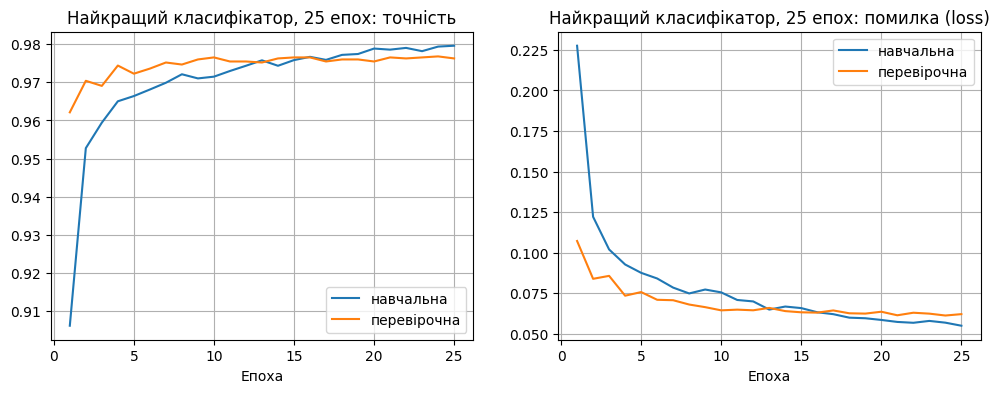

  епох 5: навчальна 96.64%, перевірочна 97.23%
  епох 10: навчальна 97.15%, перевірочна 97.65%
  епох 15: навчальна 97.58%, перевірочна 97.65%
  епох 20: навчальна 97.89%, перевірочна 97.55%
  епох 25: навчальна 97.96%, перевірочна 97.63%
найкраще: epochs = 10


In [19]:
# кількість епох: навчаємо 25 епох і дивимось на точність після 5, 10, 15, 20, 25 епох
clf_e, hist_e = run_config(current, 25)
plot_history(hist_e, 'Найкращий класифікатор, 25 епох')
best_epochs = max([5, 10, 15, 20, 25], key=lambda e: hist_e.history['val_accuracy'][e - 1])
for e in [5, 10, 15, 20, 25]:
    results.append(dict(current, epochs=e, експеримент='7. Кількість епох', train_acc=hist_e.history['accuracy'][e - 1],
                        val_acc=hist_e.history['val_accuracy'][e - 1], val_loss=hist_e.history['val_loss'][e - 1]))
    print(f"  епох {e}: навчальна {hist_e.history['accuracy'][e - 1]*100:.2f}%, перевірочна {hist_e.history['val_accuracy'][e - 1]*100:.2f}%")
current['epochs'] = best_epochs
print('найкраще: epochs =', best_epochs)

### Результати підбору гіперпараметрів

In [20]:
pd.set_option('display.width', 200)
table = pd.DataFrame(results)[['експеримент', 'dense', 'dropout', 'extra_dense', 'optimizer', 'lr', 'batch', 'epochs',
                                'train_acc', 'val_acc', 'val_loss']]
table.to_csv('hyperparameters.csv', index=False)
print('Найкращі гіперпараметри:', current)
table

Найкращі гіперпараметри: {'dense': 512, 'dropout': 0.5, 'extra_dense': 128, 'optimizer': 'sgd', 'lr': 0.001, 'batch': 25, 'epochs': 10}


,експеримент,dense,dropout,extra_dense,optimizer,lr,batch,epochs,train_acc,val_acc,val_loss
0,1. Кількість нейронів у шарі Dense,32,0.50,0,adam,0.000010,25,10,0.966514,0.972000,0.070298
1,1. Кількість нейронів у шарі Dense,128,0.50,0,adam,0.000010,25,10,0.974171,0.976800,0.063563
2,1. Кількість нейронів у шарі Dense,256,0.50,0,adam,0.000010,25,10,0.977771,0.978400,0.061879
3,1. Кількість нейронів у шарі Dense,512,0.50,0,adam,0.000010,25,10,0.980343,0.979733,0.059933
4,1. Кількість нейронів у шарі Dense,1024,0.50,0,adam,0.000010,25,10,0.984686,0.979200,0.059684
5,2. Dropout,512,0.25,0,adam,0.000010,25,10,0.986343,0.976000,0.062473
6,2. Dropout,512,0.50,0,adam,0.000010,25,10,0.980743,0.978933,0.059068
7,2. Dropout,512,0.60,0,adam,0.000010,25,10,0.978743,0.976533,0.059858
8,2. Dropout,512,0.80,0,adam,0.000010,25,10,0.970514,0.976267,0.062531
9,3. Додатковий шар Dense,512,0.50,0,adam,0.000010,25,10,0.982000,0.976000,0.061967


## Перенесення навчання з найкращими гіперпараметрами

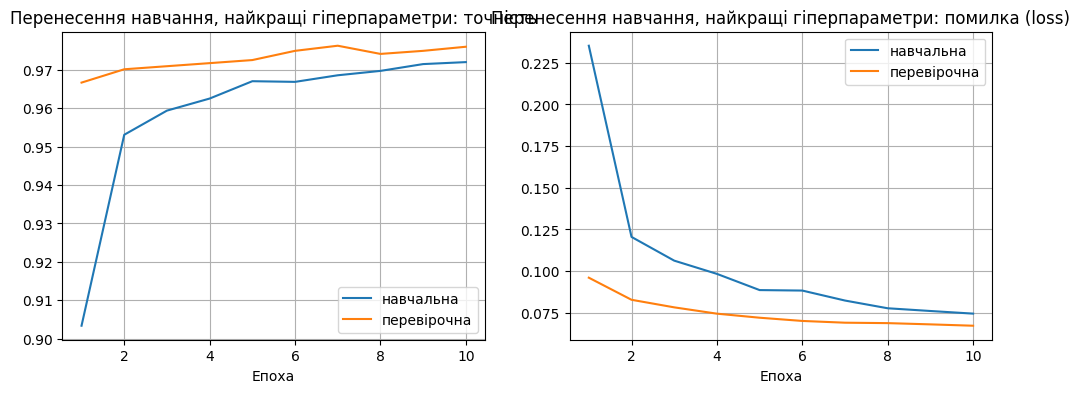

Точність на тестових даних (перенесення навчання, найкращі гіперпараметри): 97.04%


In [21]:
# перенесення навчання з найкращими гіперпараметрами (класифікатор на замороженій мережі)
clf_best, hist_tl = run_config(current, current['epochs'])
plot_history(hist_tl, 'Перенесення навчання, найкращі гіперпараметри')
scores_tl = clf_best.evaluate(test_features, test_labels, verbose=0)
print("Точність на тестових даних (перенесення навчання, найкращі гіперпараметри): %.2f%%" % (scores_tl[1] * 100))
head_weights = clf_best.get_weights()

## Тонке налаштування (Fine Tuning)

In [22]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, BatchNormalization
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.utils import load_img, img_to_array

# Константи
train_dir = 'train'
val_dir = 'val'
test_dir = 'test'
img_width, img_height = 150, 150
input_shape = (img_width, img_height, 3)

# Генератори
datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

def make_generator(directory, batch_size=64, shuffle=False):
    return datagen.flow_from_directory(directory,
                                       target_size=(img_width, img_height),
                                       batch_size=batch_size,
                                       class_mode='binary',
                                       shuffle=shuffle)

def load_base():
    net = ResNet50(weights='imagenet',
                   include_top=False,
                   input_shape=input_shape,
                   pooling='avg')
    net.trainable = False
    return net

In [23]:
def unfreeze(net, n_blocks):
    """Розморожуємо останні стадії ResNet50 (conv5 або conv4 і conv5); шари BatchNormalization залишаються замороженими."""
    stages = {1: ('conv5_',), 2: ('conv4_', 'conv5_')}[n_blocks]
    net.trainable = True
    for layer in net.layers:
        layer.trainable = layer.name.startswith(stages) and not isinstance(layer, BatchNormalization)


def fine_tune(n_blocks):
    """Тонке налаштування: свіжа згорткова частина + навчений класифікатор, розморожено n_blocks останніх блоків."""
    net = load_base()
    clf = create_classifier(current, net.output_shape[1:])
    clf.set_weights(head_weights)                      # класифікатор уже навчений на замороженій мережі
    unfreeze(net, n_blocks)
    model = Sequential()
    model.add(Input(shape=input_shape))
    model.add(net)
    model.add(clf)
    # мала швидкість навчання, щоб не втратити результати попереднього навчання (як у лекції)
    model.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=1e-5), metrics=['accuracy'])
    trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    print(f"Розморожено блоків: {n_blocks} (conv5 / conv4+conv5), параметрів навчається: {trainable:,}")
    return model


# генератори з перемішуванням для донавчання на зображеннях
ft_train_generator = make_generator(train_dir, batch_size=current['batch'], shuffle=True)
ft_epochs = 3                                      # для тонкого налаштування достатньо 2-3 епох (лекція)

Found 17500 images belonging to 2 classes.


### Розморожено 1 блок

Розморожено блоків: 1 (conv5 / conv4+conv5), параметрів навчається: 16,068,353
Epoch 1/3
700/700 ━━━━━━━━━━━━━━━━━━━━ 95s 108ms/step - accuracy: 0.9757 - loss: 0.0637 - val_accuracy: 0.9784 - val_loss: 0.0570
Epoch 2/3
700/700 ━━━━━━━━━━━━━━━━━━━━ 62s 89ms/step - accuracy: 0.9909 - loss: 0.0261 - val_accuracy: 0.9811 - val_loss: 0.0646
Epoch 3/3
700/700 ━━━━━━━━━━━━━━━━━━━━ 63s 90ms/step - accuracy: 0.9959 - loss: 0.0127 - val_accuracy: 0.9811 - val_loss: 0.0712


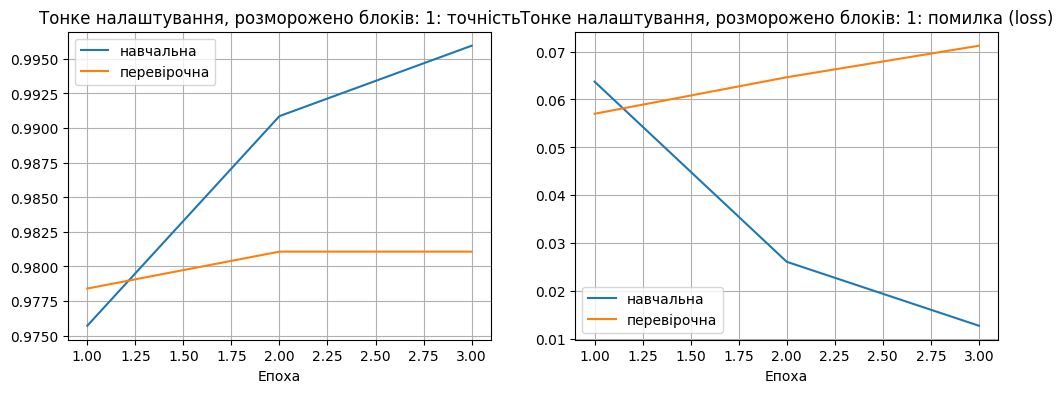

Точність на тестових даних (тонке налаштування, блоків: 1): 98.08%


In [24]:
model_ft1 = fine_tune(1)
history_ft1 = model_ft1.fit(ft_train_generator,
                              steps_per_epoch=len(ft_train_generator),
                              epochs=ft_epochs,
                              validation_data=val_generator,
                              validation_steps=len(val_generator))
plot_history(history_ft1, 'Тонке налаштування, розморожено блоків: 1')
scores_ft1 = model_ft1.evaluate(test_generator, steps=len(test_generator), verbose=0)
print("Точність на тестових даних (тонке налаштування, блоків: 1): %.2f%%" % (scores_ft1[1] * 100))

### Розморожено 2 блоки

Розморожено блоків: 2 (conv5 / conv4+conv5), параметрів навчається: 23,156,481
Epoch 1/3
700/700 ━━━━━━━━━━━━━━━━━━━━ 110s 126ms/step - accuracy: 0.9760 - loss: 0.0652 - val_accuracy: 0.9747 - val_loss: 0.0634
Epoch 2/3
700/700 ━━━━━━━━━━━━━━━━━━━━ 82s 117ms/step - accuracy: 0.9945 - loss: 0.0173 - val_accuracy: 0.9789 - val_loss: 0.0762
Epoch 3/3
700/700 ━━━━━━━━━━━━━━━━━━━━ 81s 116ms/step - accuracy: 0.9955 - loss: 0.0129 - val_accuracy: 0.9808 - val_loss: 0.0744


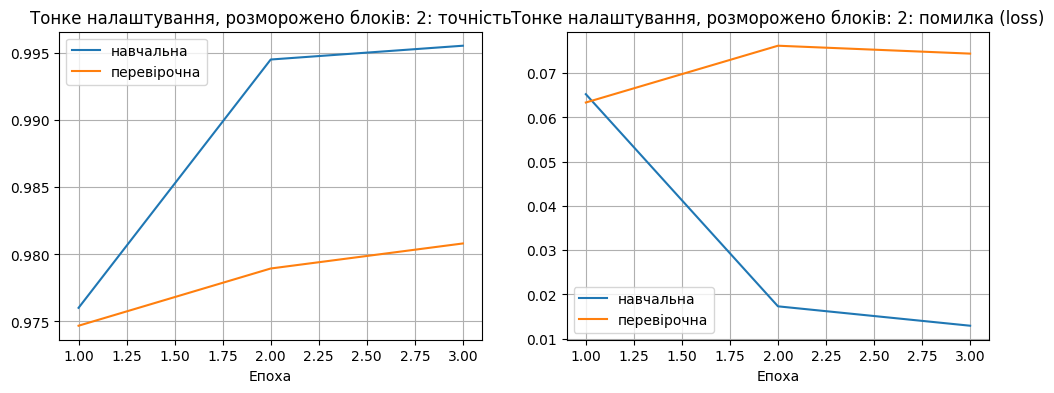

Точність на тестових даних (тонке налаштування, блоків: 2): 97.81%


In [25]:
model_ft2 = fine_tune(2)
history_ft2 = model_ft2.fit(ft_train_generator,
                              steps_per_epoch=len(ft_train_generator),
                              epochs=ft_epochs,
                              validation_data=val_generator,
                              validation_steps=len(val_generator))
plot_history(history_ft2, 'Тонке налаштування, розморожено блоків: 2')
scores_ft2 = model_ft2.evaluate(test_generator, steps=len(test_generator), verbose=0)
print("Точність на тестових даних (тонке налаштування, блоків: 2): %.2f%%" % (scores_ft2[1] * 100))

## Порівняння і збереження найкращої моделі на Google Диск

In [26]:
lab8_acc = 97.52   # точність на тестових даних у лабораторній роботі 8 (без тонкого налаштування)
compare = pd.DataFrame([
    ['Лабораторна 8: перенесення навчання', lab8_acc],
    ['Перенесення навчання, найкращі гіперпараметри', scores_tl[1] * 100],
    ['Тонке налаштування, розморожено 1 блок', scores_ft1[1] * 100],
    ['Тонке налаштування, розморожено 2 блоки', scores_ft2[1] * 100]],
    columns=['модель', 'точність на тестових, %'])
print(compare.round(2))

best_model, best_name = (model_ft1, '1 блок') if scores_ft1[1] >= scores_ft2[1] else (model_ft2, '2 блоки')
print('Найкраща модель: тонке налаштування,', best_name)

save_dir = '/content/drive/MyDrive/Lab9_models'
os.makedirs(save_dir, exist_ok=True)
best_model.save(os.path.join(save_dir, 'resnet50_finetuned.h5'), include_optimizer=False)
table.to_csv(os.path.join(save_dir, 'resnet50_finetuned_hyperparameters.csv'), index=False)
!ls -lh {save_dir}

                                          модель  точність на тестових, %
0            Лабораторна 8: перенесення навчання                    97.52
1  Перенесення навчання, найкращі гіперпараметри                    97.04
2         Тонке налаштування, розморожено 1 блок                    98.08
3        Тонке налаштування, розморожено 2 блоки                    97.81
Найкраща модель: тонке налаштування, 1 блок
total 286M
-rw------- 1 root root 102M Oct 26 14:50 inceptionv3_finetuned.h5
-rw------- 1 root root 3.8K Oct 26 14:50 inceptionv3_finetuned_hyperparameters.csv
-rw------- 1 root root  95M Oct 29 21:26 resnet50_finetuned.h5
-rw------- 1 root root 3.8K Oct 29 21:26 resnet50_finetuned_hyperparameters.csv
-rw------- 1 root root  90M Oct 26 14:22 vgg16_finetuned.h5
-rw------- 1 root root 3.9K Oct 26 14:22 vgg16_finetuned_hyperparameters.csv


## Розпізнавання власних зображень (ті самі, що в лабораторній роботі 7)

In [27]:
# копіюємо зображення з папки images_cats_dogs на Google Диску в робочий каталог
img_dirs = glob.glob('/content/drive/MyDrive/**/images_cats_dogs', recursive=True)
print(img_dirs)
assert img_dirs, 'Папку images_cats_dogs не знайдено на Google Диску'
for f in glob.glob(os.path.join(img_dirs[0], '*.jpg')):
    shutil.copy(f, '/content/')
print(len(glob.glob('/content/*.jpg')), 'зображень')

['/content/drive/MyDrive/Deep learning/images_cats_dogs']
47 зображень


In [28]:
def prepare(x):
    """Обробка зображення для ResNet50, як у генераторі."""
    return preprocess_input(x)


def recognize(pattern, title):
    """Розпізнає всі зображення, що відповідають шаблону pattern, і показує їх з відповіддю мережі.
    Правильна відповідь береться з назви файлу: cat_... або dog_... (hard_cat_..., crop_dog_... тощо)."""
    names = sorted(glob.glob(pattern))
    cols = 5
    rows = (len(names) + cols - 1) // cols
    plt.figure(figsize=(3 * cols, 3.4 * rows), dpi=60)
    correct = 0
    for i, fn in enumerate(names):
        img = load_img(fn, target_size=(img_width, img_height))
        x = prepare(img_to_array(img))                          # така сама обробка, як у генераторі
        x = np.expand_dims(x, axis=0)
        p = float(best_model.predict(x, verbose=0)[0][0])     # ймовірність класу dogs
        pred = 'dog' if p > 0.5 else 'cat'
        true = 'dog' if 'dog' in os.path.basename(fn) else 'cat'
        correct += pred == true
        conf = p if pred == 'dog' else 1 - p
        print(f"{os.path.basename(fn)}: правильно - {true}, мережа - {pred} ({conf*100:.1f}%) {'✓' if pred == true else '✗'}")
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"{os.path.basename(fn)}\n{pred} ({conf*100:.1f}%)", color='green' if pred == true else 'red')
        plt.axis('off')
    plt.suptitle(title)
    plt.show()
    print(f"Правильно розпізнано: {correct} з {len(names)}")

### 10 котів і 10 собак

cat_01.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_02.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_03.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_04.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_05.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_06.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_07.jpg: правильно - cat, мережа - cat (99.4%) ✓
cat_08.jpg: правильно - cat, мережа - dog (59.0%) ✗
cat_09.jpg: правильно - cat, мережа - dog (54.8%) ✗
cat_10.jpg: правильно - cat, мережа - dog (54.3%) ✗


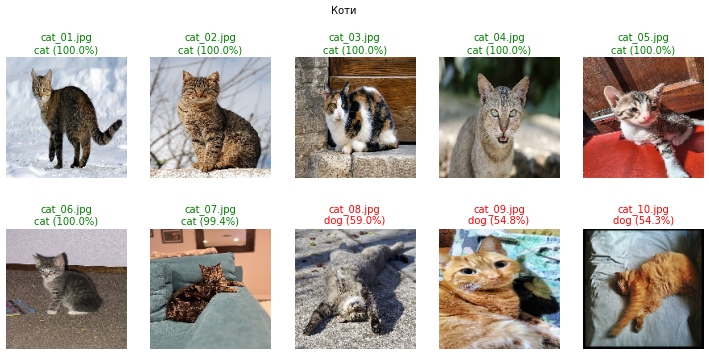

Правильно розпізнано: 7 з 10
dog_01.jpg: правильно - dog, мережа - dog (92.4%) ✓
dog_02.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_03.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_04.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_05.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_07.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_08.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_09.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_10.jpg: правильно - dog, мережа - dog (100.0%) ✓


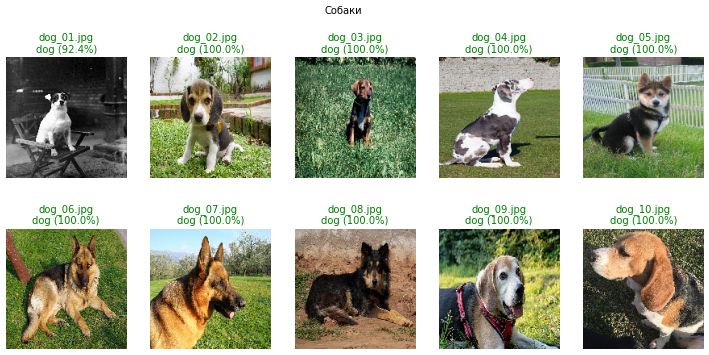

Правильно розпізнано: 10 з 10


In [29]:
recognize('cat_*.jpg', 'Коти')
recognize('dog_*.jpg', 'Собаки')

### Складні зображення

hard_cat_01.jpg: правильно - cat, мережа - cat (71.6%) ✓
hard_cat_02.jpg: правильно - cat, мережа - cat (98.1%) ✓
hard_cat_03.jpg: правильно - cat, мережа - cat (97.8%) ✓
hard_cat_04.jpg: правильно - cat, мережа - cat (100.0%) ✓
hard_cat_05.jpg: правильно - cat, мережа - dog (90.1%) ✗
hard_cat_06.jpg: правильно - cat, мережа - cat (99.9%) ✓
hard_cat_07.jpg: правильно - cat, мережа - cat (100.0%) ✓
hard_cat_08.jpg: правильно - cat, мережа - cat (100.0%) ✓
hard_cat_09.jpg: правильно - cat, мережа - dog (93.4%) ✗
hard_cat_10.jpg: правильно - cat, мережа - cat (91.4%) ✓
hard_dog_01.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_02.jpg: правильно - dog, мережа - dog (99.3%) ✓
hard_dog_03.jpg: правильно - dog, мережа - dog (96.0%) ✓
hard_dog_04.jpg: правильно - dog, мережа - dog (99.6%) ✓
hard_dog_05.jpg: правильно - dog, мережа - dog (90.5%) ✓
hard_dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_07.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_08.jpg: правильн

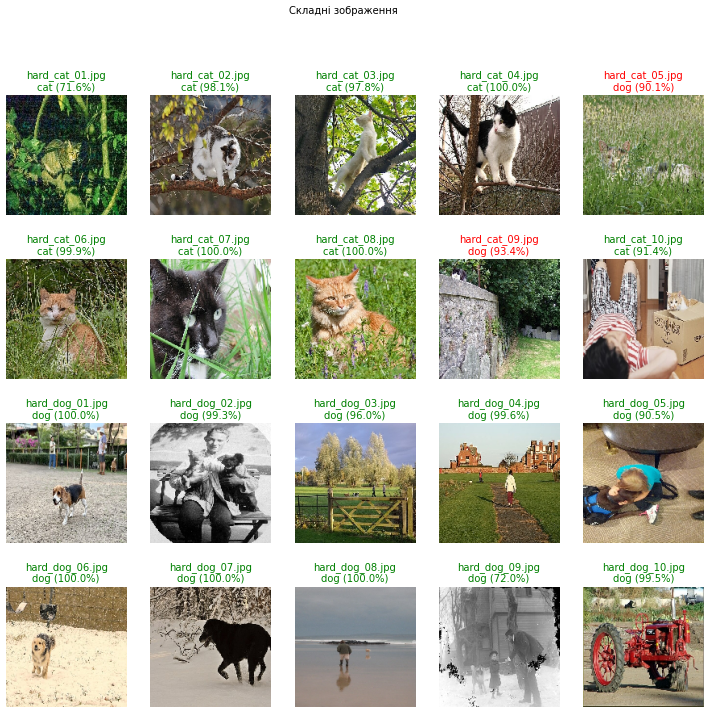

Правильно розпізнано: 18 з 20


In [30]:
recognize('hard_*.jpg', 'Складні зображення')

### Обрізані зображення

crop_cat_02.jpg: правильно - cat, мережа - cat (100.0%) ✓
crop_cat_03.jpg: правильно - cat, мережа - cat (76.8%) ✓
crop_cat_05.jpg: правильно - cat, мережа - cat (99.4%) ✓
crop_cat_06.jpg: правильно - cat, мережа - cat (100.0%) ✓
crop_cat_07.jpg: правильно - cat, мережа - cat (100.0%) ✓
crop_cat_08.jpg: правильно - cat, мережа - cat (100.0%) ✓
crop_dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓


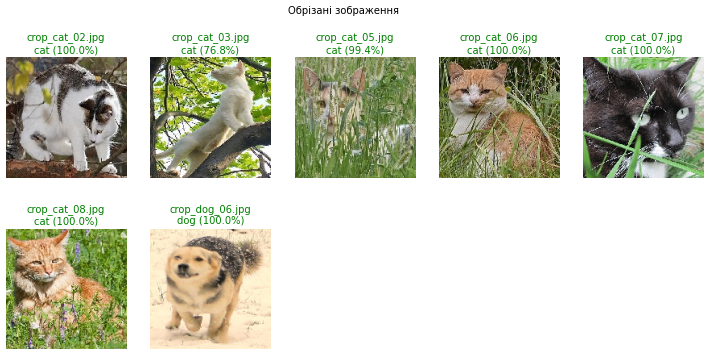

Правильно розпізнано: 7 з 7


In [31]:
recognize('crop_*.jpg', 'Обрізані зображення')